# Preparación de datos (Favorita)

Configuración única por integrante, antes de correr esta sección:

1. Aceptar las reglas de la competencia en Kaggle: https://www.kaggle.com/competitions/store-sales-time-series-forecasting/rules
2. Generar un token en https://www.kaggle.com/settings/api → **Generate New Token**. El token (empieza con `KGAT_`) se muestra una sola vez: cópialo.
3. Ejecutar las celdas de abajo. La celda de credenciales va a pedir que pegues ese token (queda solo en el runtime remoto de Colab, nunca en el repo).

El CLI de `kaggle` ya no usa `kaggle.json` con `username`+`key` (Basic Auth); usa este token único vía `~/.kaggle/access_token`. `files.upload()` tampoco funciona desde la extensión de Colab en VS Code (depende de la interfaz web de colab.research.google.com), por eso el token se pide con `getpass`.

In [1]:
!pip install -q -U kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.2/140.2 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 290.9/290.9 kB 29.9 MB/s eta 0:00:00


In [2]:
import os
from getpass import getpass

kaggle_token = getpass("Kaggle API token (KGAT_...): ")

kaggle_dir = os.path.expanduser("~/.kaggle")
os.makedirs(kaggle_dir, exist_ok=True)
token_path = os.path.join(kaggle_dir, "access_token")
with open(token_path, "w") as f:
    f.write(kaggle_token.strip())
os.chmod(token_path, 0o600)

In [3]:
import os

os.makedirs("/content/data", exist_ok=True)
!kaggle competitions download -c store-sales-time-series-forecasting -p /content/data
!unzip -o -q /content/data/store-sales-time-series-forecasting.zip -d /content/data

100% 21.4M/21.4M [00:02<00:00, 10.6MB/s]



In [4]:
import pandas as pd

train = pd.read_csv("/content/data/train.csv", parse_dates=["date"])
train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


## Selección de tienda y familias

Criterio (issue #2): elegir la tienda de mayor volumen de ventas entre las que tienen menos de 20% de días en cero (umbral laxo a nivel tienda, porque mezclar las 33 familias —incluidas nichos casi siempre en cero, como libros o cuidado de bebé— infla el % agregado). Para las familias dentro de esa tienda, umbral más estricto de 10% (ahí cada serie es la que de verdad se modela).

In [5]:
stores = pd.read_csv("/content/data/stores.csv")

store_stats = (
    train.groupby("store_nbr")
    .agg(volumen=("sales", "sum"), pct_ceros=("sales", lambda s: (s == 0).mean()))
    .reset_index()
)
store_stats["pct_ceros"] = (store_stats["pct_ceros"] * 100).round(2)
store_stats = store_stats.merge(stores, on="store_nbr").sort_values("volumen", ascending=False)
store_stats

,store_nbr,volumen,pct_ceros,city,state,type,cluster
43,44,6.208755e+07,17.95,Quito,Pichincha,A,5
44,45,5.449801e+07,19.36,Quito,Pichincha,A,11
46,47,5.094831e+07,18.95,Quito,Pichincha,A,14
2,3,5.048191e+07,18.14,Quito,Pichincha,D,8
48,49,4.342010e+07,19.35,Quito,Pichincha,A,11
45,46,4.189606e+07,19.32,Quito,Pichincha,A,14
47,48,3.593313e+07,21.32,Quito,Pichincha,A,14
50,51,3.291149e+07,20.12,Guayaquil,Guayas,A,17
7,8,3.049429e+07,19.93,Quito,Pichincha,D,8
49,50,2.865302e+07,20.65,Ambato,Tungurahua,A,14


In [6]:
STORE_ZERO_THRESHOLD = 20  # % de días en cero, a nivel tienda (mezcla las 33 familias)

candidatos = store_stats[store_stats["pct_ceros"] < STORE_ZERO_THRESHOLD]
selected_store = candidatos.sort_values("volumen", ascending=False).iloc[0]
selected_store_nbr = int(selected_store["store_nbr"])

print(
    f"Tienda elegida: {selected_store_nbr} "
    f"(volumen={selected_store['volumen']:.0f}, % ceros={selected_store['pct_ceros']:.2f}%, "
    f"ciudad={selected_store['city']}, tipo={selected_store['type']}, cluster={selected_store['cluster']})"
)

Tienda elegida: 44 (volumen=62087553, % ceros=17.95%, ciudad=Quito, tipo=A, cluster=5)


In [7]:
family_stats = (
    train[train["store_nbr"] == selected_store_nbr]
    .groupby("family")
    .agg(volumen=("sales", "sum", ), pct_ceros=("sales", lambda s: (s == 0).mean()))
    .reset_index()
)
family_stats["pct_ceros"] = (family_stats["pct_ceros"] * 100).round(2)
family_stats["volumen"] = family_stats["volumen"].round(2)
family_stats.sort_values("volumen", ascending=False)

,family,volumen,pct_ceros
12,GROCERY I,16386055.04,0.30
3,BEVERAGES,13417859.00,0.30
30,PRODUCE,10666058.48,4.81
7,CLEANING,4308260.00,0.30
8,DAIRY,4277954.00,0.30
5,BREAD/BAKERY,2333058.28,0.30
28,POULTRY,2086943.63,0.30
24,MEATS,1636611.01,0.30
10,EGGS,1091864.00,0.30
11,FROZEN FOODS,1021094.49,0.30


In [8]:
FAMILY_ZERO_THRESHOLD = 10  # % de días en cero, a nivel familia (la serie que se modela)
N_FAMILIES = 5

selected_families = (
    family_stats[family_stats["pct_ceros"] < FAMILY_ZERO_THRESHOLD]
    .sort_values("volumen", ascending=False)
    .head(N_FAMILIES)
)

print(f"Familias elegidas para la tienda {selected_store_nbr}:")
selected_families

Familias elegidas para la tienda 44:


,family,volumen,pct_ceros
12,GROCERY I,16386055.04,0.30
3,BEVERAGES,13417859.00,0.30
30,PRODUCE,10666058.48,4.81
7,CLEANING,4308260.00,0.30
8,DAIRY,4277954.00,0.30


In [9]:
train_1 = train[(train["store_nbr"] == selected_store_nbr) & (train["family"].isin(selected_families["family"]))]
train_1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8420 entries, 1257 to 3000390
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           8420 non-null   int64         
 1   date         8420 non-null   datetime64[ns]
 2   store_nbr    8420 non-null   int64         
 3   family       8420 non-null   object        
 4   sales        8420 non-null   float64       
 5   onpromotion  8420 non-null   int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 460.5+ KB


## EDA temporal (issue #3)

Tienda 44, familias GROCERY I, BEVERAGES, PRODUCE, CLEANING, DAIRY. Para estas gráficas las ventas se agregan: `ventas` = suma diaria de las 5 familias (una sola serie, no una por familia).

Se agregan dos fuentes externas, a nivel diario:
- `transactions.csv`: transacciones de la tienda 44.
- `oil.csv`: precio WTI del petróleo (nacional, no por tienda). Solo reporta días hábiles; los fines de semana/feriados se llenan con forward fill (último precio conocido).

In [10]:
import matplotlib.pyplot as plt

oil = pd.read_csv("/content/data/oil.csv", parse_dates=["date"])
transactions = pd.read_csv("/content/data/transactions.csv", parse_dates=["date"])
holidays = pd.read_csv("/content/data/holidays_events.csv", parse_dates=["date"])

daily = (
    train_1.groupby("date")["sales"]
    .sum()
    .reset_index()
    .rename(columns={"sales": "ventas"})
)

tx_store = transactions.loc[transactions["store_nbr"] == selected_store_nbr, ["date", "transactions"]]
daily = daily.merge(tx_store, on="date", how="left")

oil_wti = oil.rename(columns={"dcoilwtico": "precio_petroleo"})[["date", "precio_petroleo"]]
daily = daily.merge(oil_wti, on="date", how="left").sort_values("date")
daily["precio_petroleo"] = daily["precio_petroleo"].ffill()

daily.head()

,date,ventas,transactions,precio_petroleo
0,2013-01-01,0.0,NaN,NaN
1,2013-01-02,21984.0,4821.0,93.14
2,2013-01-03,15108.0,3618.0,92.97
3,2013-01-04,16130.0,4169.0,93.12
4,2013-01-05,23142.0,4921.0,93.12


### 1. Tendencia de ventas diarias

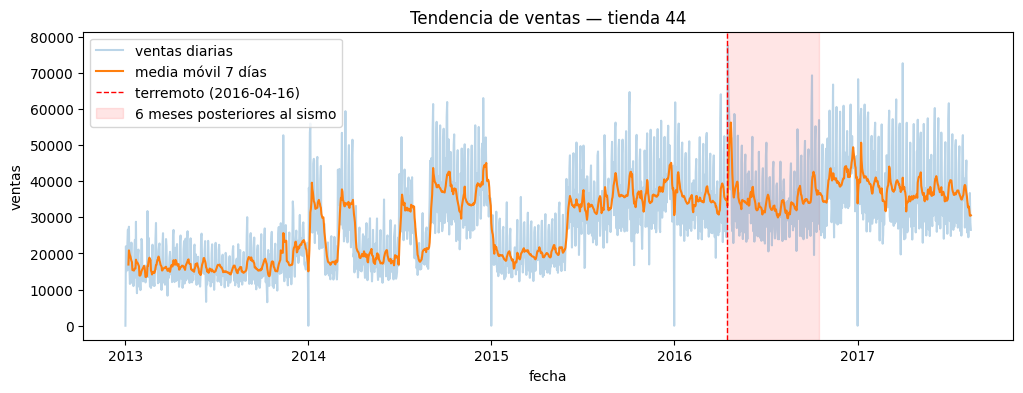

In [21]:
terremoto = pd.Timestamp("2016-04-16")
terremoto_fin = terremoto + pd.DateOffset(months=6)

daily_ma = daily.set_index("date")["ventas"].rolling(7).mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily["date"], daily["ventas"], alpha=0.3, label="ventas diarias")
ax.plot(daily_ma.index, daily_ma.values, color="C1", label="media móvil 7 días")
ax.axvline(terremoto, color="red", linestyle="--", linewidth=1, label="terremoto (2016-04-16)")
ax.axvspan(terremoto, terremoto_fin, color="red", alpha=0.1, label="6 meses posteriores al sismo")
ax.set_title(f"Tendencia de ventas — tienda {selected_store_nbr}")
ax.set_xlabel("fecha")
ax.set_ylabel("ventas")
ax.legend()
plt.show()

**Interpretación:** 
- Se observa una tendencia general creciente durante el período de observación.
- Se toma nota del comportamiento inestable durante el año 2014 y primer cuatrimestre de 2015, el comportamiento es relativamente estable desde entonces.
- Se observa un pico dramático inmediatamente después del terremoto de abril de 2016, una anomalía relacionada con circunstancias excepcionales.

### 2. Patrón por día de la semana

/tmp/ipykernel_1756/959696494.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(datos_por_dia, labels=[d[:3] for d in orden_dias])


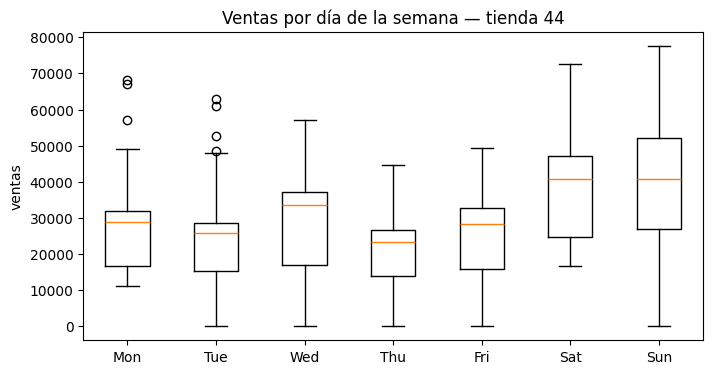

In [12]:
daily["dia_semana"] = daily["date"].dt.day_name()
orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
datos_por_dia = [daily.loc[daily["dia_semana"] == d, "ventas"] for d in orden_dias]

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(datos_por_dia, labels=[d[:3] for d in orden_dias])
ax.set_title(f"Ventas por día de la semana — tienda {selected_store_nbr}")
ax.set_ylabel("ventas")
plt.show()

**Insight:** Se evidencia un ligero patrón de aumento de las ventas en promedio así como máximas en los fines de semana.

### 3. Patrón quincenal (día del mes)

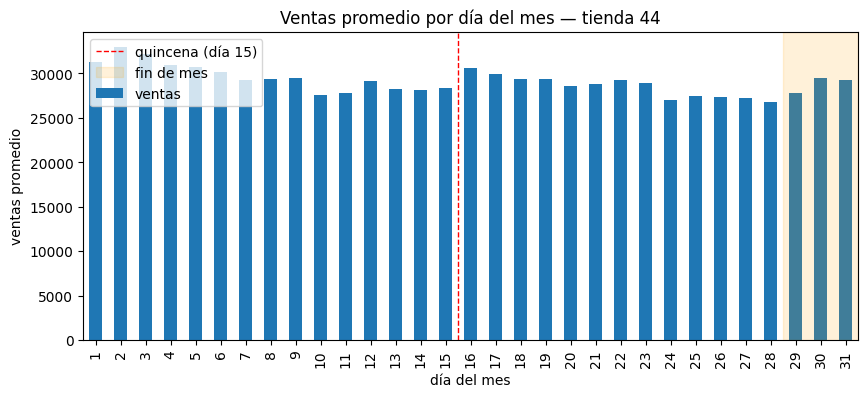

In [13]:
daily["dia_mes"] = daily["date"].dt.day
ventas_por_dia_mes = daily.groupby("dia_mes")["ventas"].mean()
n_dias = ventas_por_dia_mes.index.max()

fig, ax = plt.subplots(figsize=(10, 4))
ventas_por_dia_mes.plot(kind="bar", ax=ax)
ax.axvline(x=14.5, color="red", linestyle="--", linewidth=1, label="quincena (día 15)")
ax.axvspan(n_dias - 3.5, n_dias - 0.5, color="orange", alpha=0.15, label="fin de mes")
ax.set_title(f"Ventas promedio por día del mes — tienda {selected_store_nbr}")
ax.set_xlabel("día del mes")
ax.set_ylabel("ventas promedio")
ax.legend()
plt.show()

**Insight:** Aunque la diferencia no es radical, los días 16 y 2 son los máximos de ventas de cada quincena y se observa la disminución gradual de las ventas durante el mes hasta la próxima quincena, por lo que se puede inferir una correlación negativa leve entre los días desde la última quincena y las ventas del día.

**Decisión:** Añadir días desde última quincena como feature.

### 4. Festivos vs días normales

Un día cuenta como festivo si: es festivo `National` no transferido, o `Regional`/`Local` cuyo `locale_name` coincide con el estado/ciudad de la tienda (Pichincha/Quito), o es un `Transfer` (el día que realmente se observa). `Work Day` no cuenta como festivo (es un día laboral de recuperación).

/tmp/ipykernel_1756/206551232.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([ventas_normal, ventas_festivo], labels=["normal", "festivo"])


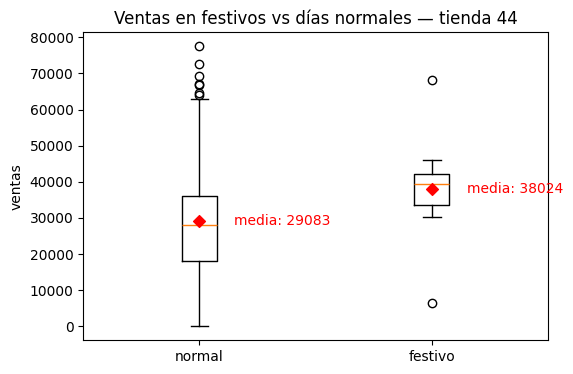

In [19]:
selected_store_city = selected_store["city"]
selected_store_state = selected_store["state"]


def aplica_festivo(row):
    if row["transferred"]:
        return False
    if row["type"] == "National":
        return True
    if row["type"] == "Regional" and row["locale_name"] == selected_store_state:
        return True
    if row["type"] == "Local" and row["locale_name"] == selected_store_city:
        return True
    if row["type"] == "Transfer":
        return True
    return False


fechas_festivas = set(holidays.loc[holidays.apply(aplica_festivo, axis=1), "date"])
daily["es_festivo"] = daily["date"].isin(fechas_festivas)

ventas_normal = daily.loc[~daily["es_festivo"], "ventas"]
ventas_festivo = daily.loc[daily["es_festivo"], "ventas"]

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([ventas_normal, ventas_festivo], labels=["normal", "festivo"])
for i, serie in enumerate([ventas_normal, ventas_festivo], start=1):
    promedio = serie.mean()
    ax.annotate(
        f"media: {promedio:.0f}",
        xy=(i, promedio),
        xytext=(i + 0.15, promedio),
        va="center",
        color="red",
    )
    ax.scatter(i, promedio, color="red", marker="D", zorder=3)
ax.set_title(f"Ventas en festivos vs días normales — tienda {selected_store_nbr}")
ax.set_ylabel("ventas")
plt.show()

**Insight:** Se observa una clara relación entre los días festivos y un aumento en el promedio y la distribución general de las ventas. Siendo el 25% de los días festivos con menos ventas aún mayor que el promedio de las ventas en un día normal.

**Decisión:** Incluir festivos en el modelo con una feature "es festivo" en la agregación de ventas por día.

### 5. Transacciones a lo largo del año

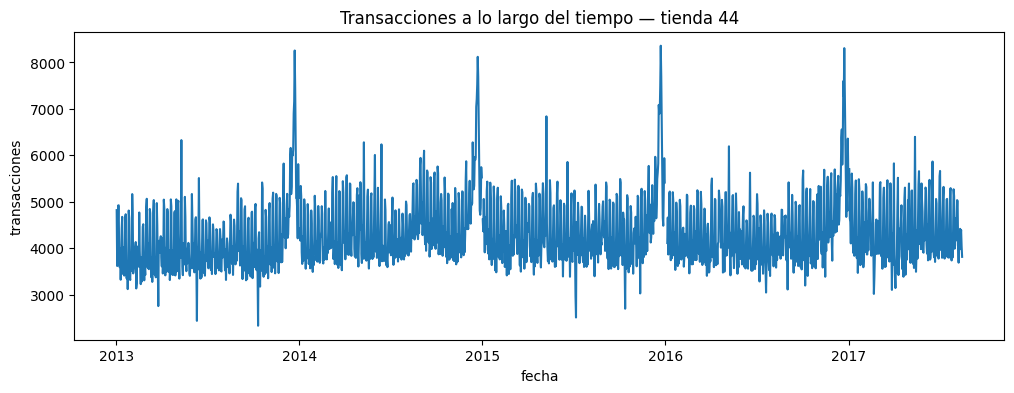

In [15]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily["date"], daily["transactions"])
ax.set_title(f"Transacciones a lo largo del tiempo — tienda {selected_store_nbr}")
ax.set_xlabel("fecha")
ax.set_ylabel("transacciones")
plt.show()

**Insight:** El patrón es el esperado: volúmenes de ventas estables durante el año con picos pronunciados cerca de los últimos meses. La correlación positiva entre las transacciones y ventas permite inferir que los totales de ventas tendrán un comportamiento análogo.

### 6. Precio del petróleo vs ventas y transacciones (scatter)

Solo exploratorio: el petróleo es macro (no por tienda) y no entrará como variable al modelo.

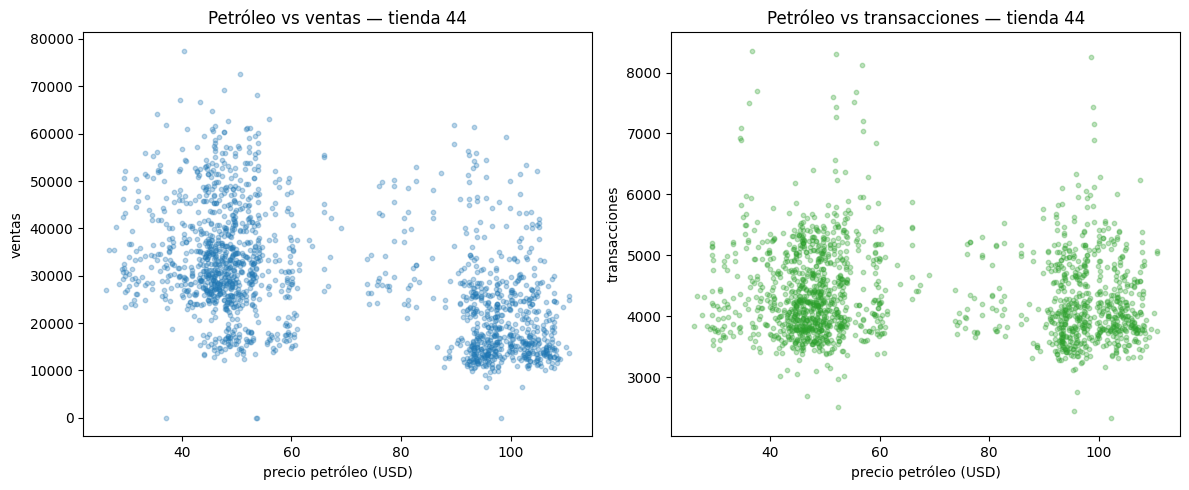

correlación petróleo-ventas: -0.497
correlación petróleo-transacciones: -0.108


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(daily["precio_petroleo"], daily["ventas"], alpha=0.3, s=10)
axes[0].set_title(f"Petróleo vs ventas — tienda {selected_store_nbr}")
axes[0].set_xlabel("precio petróleo (USD)")
axes[0].set_ylabel("ventas")

axes[1].scatter(daily["precio_petroleo"], daily["transactions"], alpha=0.3, s=10, color="C2")
axes[1].set_title(f"Petróleo vs transacciones — tienda {selected_store_nbr}")
axes[1].set_xlabel("precio petróleo (USD)")
axes[1].set_ylabel("transacciones")

plt.tight_layout()
plt.show()

print("correlación petróleo-ventas:", daily["precio_petroleo"].corr(daily["ventas"]).round(3))
print("correlación petróleo-transacciones:", daily["precio_petroleo"].corr(daily["transactions"]).round(3))

**Insight:** No se observa correlación significativa entre el precio del petróleo y la cantidad de transacciones. Sí se observa una correlación negativa moderada entre el precio del petróleo y las ventas totales, pero probablemente es espuria: el petróleo cayó de ~93 a ~26 USD entre 2013 y 2016 mientras las ventas de la tienda 44 crecían por tendencia propia; ambas series comparten tendencia temporal sin que exista una relación causal real entre ellas.

**Decisión:** No incluir el precio del petróleo en el modelo (coincide con la nota de la sección: es una variable macro, no por tienda, y su valor futuro tampoco se conoce al momento de predecir).

### 7. Transacciones vs ventas (scatter)

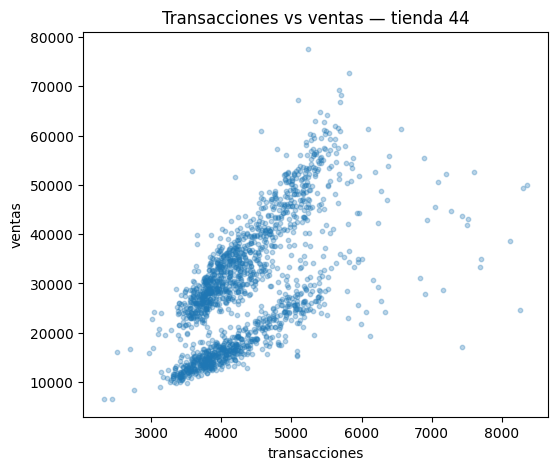

correlación: 0.616


In [17]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(daily["transactions"], daily["ventas"], alpha=0.3, s=10)
ax.set_title(f"Transacciones vs ventas — tienda {selected_store_nbr}")
ax.set_xlabel("transacciones")
ax.set_ylabel("ventas")
plt.show()

print("correlación:", daily["transactions"].corr(daily["ventas"]).round(3))

**Insight:** Se observan dos grupos claramente distinguidos de ventas, probablemente útiles para un trabajo alternativo de segmentación de clientes o análisis de tendencia de consumo. Esto no se tendrá en cuenta.